In [14]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd 

# Feature Engineering: Price Per Square Meter 


<div class = " alert alert-block alert-success"><b>Recap</b></div>
   
**Refresh - go over simpsons paradox**

Lesson 1 - Data Structures and Descriptive Stats
Lesson 2 - Visual Distributions, Outliers, and Scatter Plot
Lesson 3 - National Correlation (r = 0.59) -> state level variation was massive 

<div class = "alert alert-block alert-success"> <b>Research Question</b> </div>

**Are property prices in Mexico more influenced by property *size* or by *location*? (location effect - location premium vs. size effect - house size premium)** 

This lesson delivers the final, quantitative answer by engineering `price_per_m2`
1. We analyzing its distribution = decomposing price_per_$m^2$ `variance` into:
    -  `between-state` components and,
    -   `within-state` components
3. Then comparing it across both states and property types
      

Step 1) Price per $m^2$ as a location value proxy - making red apples and green apples comparable (different locations with different housing sizes and price discrepancy)

$$
Price \space per \space m^2 = \frac{price \space m^2}{area \space m^2}
$$

*How much value is packed in one square meter for observation i out of n observations - in other words the density of value, how much money is packed inot each unit of space.*



|High `price_per_m2` indicates:|Low `price_per_m2` indicates:|
|----|----|
|A desirable, scarce location (city center, coastal resort)|Rural or suburban location with plentiful land|
|Luxury finishes and amenities (pool, concierge, views, convinience, lifestyle estate(gyms, parks, hangouts)...etc)|Basic finishes in a less competitive market|
|Urban density where land is the scarce resource| |

<div class = "alert alert-block alert-info"><bold> Recall from Lessons 1 and 3: .assign(column_name = lambda x: expression) creates a new column or overwrites an existing one. The lambda x: pattern means "use x as a placeholder for the DataFrame at the current step of the chain, so you can reference its columns in the expression."</bold></div>

<div class = "alert alert-block alert-light">

<bold>Why <b>.describe()</b> follows the assignment <hr>

> After creating `price_per_m2`, we immediately call `.describe()` on it. This is a
> miniature version of the inspection ritual from Lesson 1 — before analyzing any
> new variable, always check its range, central tendency, and whether it has
> missing values. For `price_per_m2` specifically:
> `min` near 
</bold>
</div>

In [22]:
df = (
    pd.read_csv("./data/mexico-real-estate-combined-clean.csv")
    .assign(price_per_m2 = lambda x: x["price_usd"] / x["area_m2"])
)

print(f"Price per m\u00b2($) Statistics\n")
print(f"{df["price_per_m2"].describe()}\n")

df.head()

Price per m²($) Statistics

count    1736.000000
mean      746.728971
std       437.632824
min       126.984127
25%       497.462745
50%       625.000000
75%       822.224408
max      3906.250000
Name: price_per_m2, dtype: float64



,property_type,state,lat,lon,area_m2,price_usd,price_per_m2
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56,453.103733
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78,339.912796
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37,1028.028902
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80,628.725333
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37,513.128634


<div class = "alert alert-block alert-success"> <b>Univariate Analysis: Distribution of Space Value</b></div>

The distribution is right-skewed and the median sits to the left of the visual center of the distribution.    
This gap is a visual measure of how far the distribution deviates from symmetry. 

Histogram of `price_per_m2` with a median line: 

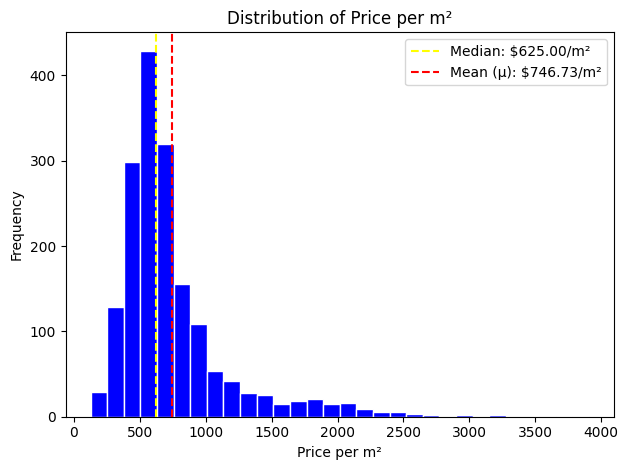

In [37]:
# Step 0) Create Figure and Axis
fig, ax = plt.subplots()

# Step 1) Create the Histogram with 30 bins 
ax.hist(df["price_per_m2"], bins = 30, color = 'blue', edgecolor="white")

# Step 1.2) Create Labels and Titles
ax.set_title("Distribution of Price per m\u00b2")
ax.set_xlabel("Price per m\u00b2")
ax.set_ylabel("Frequency")

# Step 2) Vertical Line for the Median 
median_price_per_m2 = df["price_per_m2"].median()
ax.axvline(median_price_per_m2, color = 'yellow', linestyle = '--', label = f'Median: ${median_price_per_m2:.2f}/m\u00b2')
ax.legend()

# Optional Step 2.2) Vertical Line for the Mean 
mean_price_per_m2 = df["price_per_m2"].mean()
ax.axvline(mean_price_per_m2, color = 'red', linestyle = '--', label = f'Mean (\u00b5): ${mean_price_per_m2:.2f}/m\u00b2')
ax.legend()
plt.tight_layout()

##### **$\underline{\mathbf{Statistical \space Conclusions}}$**
**Right-Skew: (long right** We have extreme values such as the maximum value of USD 3 906.25 while both the mean (USD 746.73) and the median (USD 625) are significantly smaller.   
**Median is the Measure of Central Tendancy:** Extreme values pulling the mean up. Visually Median is to the left of the center of the distribution $\therefore$ an immediate tell of a right skew. 

<div class = "alert alert-block alert-success"><b>Grouped Analysis: The Location Effect</b></div>

Now grouping the observations by state using the metric `price_m2` we get that `